# Sampling with gradients: NUTS against emcee

The densities of a compiled problem are written in JAX, so their exact
gradient is available, through the models, the covariance and the reaction
solver.  A gradient sampler, the No-U-Turn sampler ([NUTS](https://blackjax-devs.github.io/blackjax/examples/quickstart.html#nuts)) of
[Hamiltonian Monte Carlo](https://en.wikipedia.org/wiki/Hamiltonian_Monte_Carlo),
uses it to take long, directed steps instead of a random walk.  Whether that
pays depends on the problem: a NUTS draw costs tens of gradient evaluations,
while an [emcee](https://emcee.readthedocs.io/en/stable/) step costs one
density evaluation per walker.

We compare NUTS with emcee on two problems, by *effective* samples per
second, the number that decides how long a calibration takes:

1. a hierarchy with 33 parameters, where NUTS should win;
2. a 5-parameter Gaussian-process discrepancy, where it should not.

On the GP, both samplers start about the
[posterior mode](https://en.wikipedia.org/wiki/Maximum_a_posteriori_estimation) (MAP), found
by [L-BFGS-B](https://en.wikipedia.org/wiki/Limited-memory_BFGS) with the
exact gradient (`rx.optimize.find_map`, recipe 33), and the search's time is charged to each.  On the hierarchy both start from prior draws, for reasons we give there.  On the way we use the
gradient once more, for a
[Laplace approximation](https://en.wikipedia.org/wiki/Laplace%27s_approximation)
from the exact Hessian.

For reaction models with a handful of parameters, the
[sampler benchmark](/benchmarks.md) compares these two with nested sampling (dynesty) and
preconditioned Monte Carlo (pocomc), scoring each against exact or
long-run reference posteriors.  On the $p + {}^{40}\mathrm{Ca}$ optical model pocomc reaches
the reference fastest, and the reaction notebooks use it; on the funnels a
hierarchy and a GP make, the samplers that start from the prior (dynesty and pocomc) are biased.

Recipes: 16, 33, 41

In [1]:
import logging
import time

import blackjax
import corner
import emcee
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotstyle
import tinygp
from budget import QUICK_NUTS, budget  # sampler budgets, cut in CI's quick run
from scipy import stats

import rxmc as rx
from rxmc import terms as T

plotstyle.use()
logging.getLogger("emcee").setLevel(logging.ERROR)  # score() reports tau itself

## The two samplers, and how we compare them

rxmc owns no sampler; each of these is a few lines on the problem's
densities.

- **emcee** moves an ensemble of walkers, each by a
  [stretch move](https://emcee.readthedocs.io/en/stable/user/moves/) along
  the line to another walker: no gradient and no tuning, one density
  evaluation per walker per step.
- **NUTS** ([NUTS](https://blackjax-devs.github.io/blackjax/examples/quickstart.html#nuts)) follows Hamiltonian trajectories with the
  gradient and stops each one when it starts to turn back; its step size and
  mass matrix are tuned in a discarded
  [warm-up](https://blackjax-devs.github.io/blackjax/examples/quickstart.html#use-stan-s-window-adaptation).

NUTS runs on `log_posterior_unconstrained`, the posterior on
$\mathbb{R}^n$: a bounded parameter is sampled as a log or a logit, so a
trajectory never meets the $-\infty$ wall at a bound, and `to_theta` maps
the draws back (recipe 41).  Its chains run one after another; vmapped,
every chain would wait at each step for the longest trajectory.

The comparison:

- The [effective sample size](https://mc-stan.org/docs/reference-manual/analysis.html)
  (ESS) of a correlated chain is the number of independent draws that would
  estimate a posterior mean as precisely.  We take the smallest over the
  parameters of blackjax's rank-normalised *bulk*
  [ESS](https://blackjax-devs.github.io/blackjax/autoapi/blackjax/diagnostics/index.html)
  across chains, and report it per second of wall time (compilation and
  the start search included) and per thousand calls.  A call is one
  evaluation of the log posterior and, for NUTS, its gradient; ESS per call
  does not depend on the machine, and the time per call shows what a call
  costs.  The calls are split into the start search, warm-up (NUTS's
  adaptation, emcee's discarded burn-in) and sampling.
- The rank-normalised split [$\hat R$](https://en.wikipedia.org/wiki/Gelman-Rubin_statistic)
  ([Vehtari et al. 2021](https://arxiv.org/abs/1903.08008)) compares the
  spread within each half-chain with the spread between them, so it also
  catches chains that drift together.  Above about 1.01
  the chains have not yet forgotten where they started, their ESS means
  nothing, and we report the run as not converged.
- emcee's walkers are taken as chains, which flatters its ESS: they are not
  independent, since each move uses another walker.  So we also print
  emcee's own
  [integrated autocorrelation time](https://emcee.readthedocs.io/en/stable/tutorials/autocorr/)
  $\tau$, the number of steps over which a walker remembers its past; emcee
  trusts a run only when it is longer than about $50\tau$.  We report a
  run shorter than that as not converged, whatever $\hat R$ says: walkers
  that move toward one another can agree long before they have explored
  the posterior.
- NUTS reports *divergent transitions*: trajectories that met curvature too sharp for the step size and were stopped.  Where they happen, NUTS can under-explore the posterior, so we report no ESS for a run that has any.

In [2]:
def run_nuts(
    problem, starts, warmup=budget(1000), draws=budget(1000), seed=0, target=0.8
):
    """One window-adapted NUTS chain per row of ``starts``; draws in theta."""
    logdensity = problem.log_posterior_unconstrained
    t0, chains, divergent, n_warm, n_draw = time.perf_counter(), [], 0, 0, 0
    for key, theta0 in zip(jax.random.split(jax.random.key(seed), len(starts)), starts):
        k_warm, k_draw = jax.random.split(key)
        adapt = blackjax.window_adaptation(
            blackjax.nuts, logdensity, target_acceptance_rate=target, **QUICK_NUTS
        )
        (state, tuned), warm = adapt.run(
            k_warm, problem.to_unconstrained(theta0), num_steps=warmup
        )
        step = jax.jit(blackjax.nuts(logdensity, **tuned).step)

        def one_step(state, key):
            state, info = step(key, state)
            return state, (state.position, info)

        _, (zs, info) = jax.lax.scan(one_step, state, jax.random.split(k_draw, draws))
        chains.append(np.asarray(jax.vmap(problem.to_theta)(zs)))
        divergent += int(info.is_divergent.sum())
        n_warm += int(warm.info.num_integration_steps.sum())
        n_draw += int(info.num_integration_steps.sum())
    return np.stack(chains), dict(
        wall=time.perf_counter() - t0,
        warmup=n_warm,
        sampling=n_draw,
        divergences=divergent,
    )


def ball(problem, centre, n, seed=0):
    """``n`` points about ``centre``, jittered on the unconstrained scale so
    that every one is inside the support."""
    z = problem.to_unconstrained(centre)
    dz = 0.01 * np.random.default_rng(seed).standard_normal((n, problem.ndim))
    return np.array([problem.to_theta(z + d) for d in dz])


def run_emcee(problem, starts, steps, seed=0):
    """emcee from ``starts`` (one walker each), the first third discarded;
    walkers as chains."""
    n_walkers = len(starts)
    t0 = time.perf_counter()
    sampler = emcee.EnsembleSampler(
        n_walkers, problem.ndim, problem.log_posterior_batch, vectorize=True
    )
    sampler.random_state = np.random.RandomState(seed).get_state()
    sampler.run_mcmc(starts, steps, progress=False)
    kept = sampler.get_chain(discard=steps // 3)
    tau = float(np.max(sampler.get_autocorr_time(discard=steps // 3, quiet=True)))
    return np.swapaxes(kept, 0, 1), dict(
        wall=time.perf_counter() - t0,
        warmup=n_walkers * (steps // 3),
        sampling=n_walkers * (steps - steps // 3),
        tau=tau,
        steps_kept=len(kept),
    )


def overlay(runs, colours, labels, title):
    """Corner plots of several runs on shared axes, each histogram normalised."""
    ranges = [np.percentile(runs[-1][:, k], [0.2, 99.8]) for k in range(len(labels))]
    ranges = [(lo - 0.3 * (hi - lo), hi + 0.3 * (hi - lo)) for lo, hi in ranges]
    fig = None
    for run, colour in zip(runs, colours):
        fig = corner.corner(
            run,
            fig=fig,
            labels=labels,
            range=ranges,
            hist_kwargs={"density": True},
            **plotstyle.corner_kwargs(show_titles=False, color=colour),
        )
    fig.suptitle(title)
    plt.show()


def score(name, chains, info, search=None):
    """Print a sampler's cost and result, its start ``search`` (an
    ``rx.optimize`` result) charged to it; ESS only for a converged run with
    no divergences.  Returns the wall time and the ESS (None if not trusted)."""
    found = 0 if search is None else search.nfev
    wall = info["wall"] + (0 if search is None else search.wall)
    calls = found + info["warmup"] + info["sampling"]
    print(
        f"{name}: {wall:.1f} s, {calls} calls ({found} search, "
        f"{info['warmup']} warm-up, {info['sampling']} sampling), "
        f"{1e3 * wall / calls:.2f} ms per call"
    )
    # the rank-normalised diagnostics sort every draw, so a long emcee run is
    # thinned to at most 2000 draws per walker first; thinning by far less than
    # the autocorrelation time costs almost no effective draws
    thinned = chains[:, :: max(1, chains.shape[1] // 2000)]
    ess = float(np.min(blackjax.diagnostics.ess_bulk(thinned)))
    rhat = float(np.max(blackjax.diagnostics.rhat(thinned)))
    enough = "tau" not in info or info["steps_kept"] > 50 * info["tau"]
    trusted = rhat <= 1.01 and enough and info.get("divergences", 0) == 0
    if trusted:
        line = f"  ESS {ess:.0f}, {ess / wall:.2f} per s, {1e3 * ess / calls:.2f} per 1k calls"
    else:
        line = "  not trusted"
    line += f"; R-hat {rhat:.3f}"
    if "tau" in info:
        line += f", tau {info['tau']:.0f} steps" + ("" if enough else " (< 50 tau)")
    if "divergences" in info:
        line += f", {info['divergences']} divergent"
    print(line)
    return wall, ess if trusted else None

## 1. A hierarchy: where gradients pay

Thirty groups each measure a line.  They share the slope $m$, and their
intercepts scatter about a common $\mu$ with an unknown spread $\tau$,
written non-centred as $\mu + \tau\,\eta_j$ with
$\eta_j \sim \mathcal{N}(0, 1)$ (recipe 38): 33 parameters, most of them the
$\eta_j$.  (This $\tau$ is the hierarchy's spread, not emcee's
autocorrelation time.)  A stretch move proposes along the line between two
walkers, and in 33 dimensions few such lines point anywhere useful.

Here both samplers start from prior draws.  Neither point estimate is a
good start on a hierarchy.  The likelihood depends on $\mu$, $\tau$ and the
$\eta_j$ only through the intercepts $\mu + \tau\,\eta_j$, so its maximum is
not a point but a ridge, and Nelder–Mead in 33 dimensions stops wherever
its evaluation budget runs out.  The MAP is a point, but not a typical
one: the $\mathcal{N}(0, 1)$ prior rewards small $\eta_j$, so the mode
trades them for a $\tau$ well above the bulk of the posterior.

In [3]:
rng = np.random.default_rng(5)
x = np.linspace(0.0, 1.0, 5)
m = rx.Parameter("m", prior=stats.norm(0, 5), latex="m")
mu = rx.Parameter("mu", prior=stats.norm(0, 5), latex=r"\mu")
tau = rx.Parameter(
    "tau", prior=stats.halfnorm(scale=1.0), bounds=(0.0, np.inf), latex=r"\tau"
)
comps = []
for j in range(30):
    eta = rx.Parameter(f"eta_{j}", prior=stats.norm(0, 1), latex=rf"\eta_{{{j}}}")
    y = 0.8 * x + 1.0 + 0.3 * rng.normal() + rng.normal(0, 0.1, x.size)
    group = rx.Model(
        lambda x, m, mu, tau, eta: m * x + mu + tau * eta, [m, mu, tau, eta]
    )
    comps.append(rx.Comparison(rx.Dataset(x, y, 0.1 * np.ones(x.size)), group))
hierarchy = rx.Problem([rx.Constraint(comps)])
print(hierarchy.ndim, "parameters")

33 parameters


In [4]:
h_nuts, h_nuts_info = run_nuts(
    hierarchy, hierarchy.sample_prior(4, rng=1), warmup=budget(1000), draws=budget(2000)
)
h_walkers = hierarchy.sample_prior(2 * hierarchy.ndim + 2, rng=2)
h_emcee, h_emcee_info = run_emcee(hierarchy, h_walkers, steps=budget(6000))
h_nuts_wall, _ = score("NUTS", h_nuts, h_nuts_info)
h_emcee_wall, _ = score("emcee", h_emcee, h_emcee_info)

NUTS: 33.8 s, 301594 calls (0 search, 115346 warm-up, 186248 sampling), 0.11 ms per call


  ESS 453, 13.42 per s, 1.50 per 1k calls; R-hat 1.007, 0 divergent
emcee: 11.2 s, 408000 calls (0 search, 136000 warm-up, 272000 sampling), 0.03 ms per call


  not trusted; R-hat 1.505, tau 443 steps (< 50 tau)


emcee has not converged, and by its own estimate of $\tau$ its run is
too short.  Is it only a matter of a longer run?  Nearly seven times the
steps:

In [5]:
h_long, h_long_info = run_emcee(hierarchy, h_walkers, steps=budget(40000))
h_long_wall, _ = score("emcee", h_long, h_long_info)
print(
    f"NUTS: {h_nuts_wall:.0f} s; emcee: {h_emcee_wall:.0f} s, then {h_long_wall:.0f} s "
    f"for the longer run"
)

emcee: 66.7 s, 2720000 calls (0 search, 906644 warm-up, 1813356 sampling), 0.02 ms per call


  not trusted; R-hat 1.062, tau 975 steps (< 50 tau)
NUTS: 34 s; emcee: 11 s, then 67 s for the longer run


In [6]:
# what the emcee runs disagree about: the parameters with the worst split
# R-hat, and how far apart the walkers sit in log posterior
for name, chains in (("6000 steps", h_emcee), ("40000 steps", h_long)):
    thinned = chains[:, :: max(1, chains.shape[1] // 2000)]
    r = np.asarray(blackjax.diagnostics.rhat(thinned))
    worst = [f"{hierarchy.names[k]} {r[k]:.3f}" for k in np.argsort(r)[::-1][:3]]
    log_post = np.asarray(
        hierarchy.log_posterior_batch(chains.reshape(-1, hierarchy.ndim))
    )
    walker_mean = log_post.reshape(chains.shape[:2]).mean(axis=1)
    print(
        f"emcee, {name}: worst split R-hat {', '.join(worst)}; walkers' mean log "
        f"posterior spans {walker_mean.max() - walker_mean.min():.1f}"
    )

emcee, 6000 steps: worst split R-hat eta_17 1.505, eta_7 1.431, eta_15 1.408; walkers' mean log posterior spans 7.3


emcee, 40000 steps: worst split R-hat tau 1.062, eta_7 1.056, eta_18 1.052; walkers' mean log posterior spans 3.4


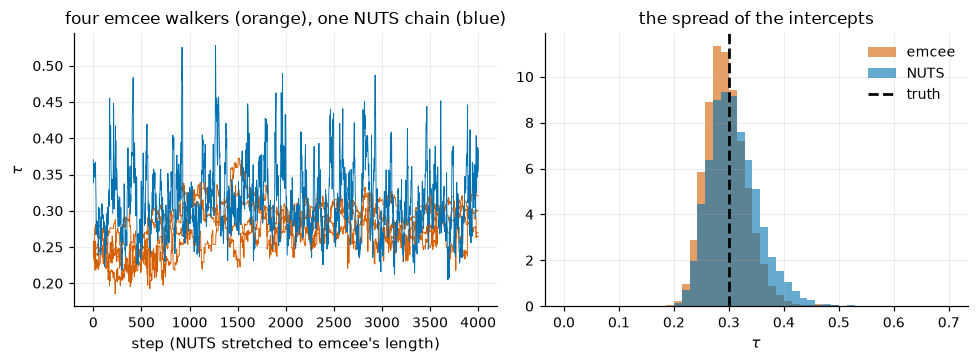

In [7]:
col = hierarchy.columns(tau).item()
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.4))
axes[0].plot(h_emcee[:4, :, col].T, lw=0.6, color=plotstyle.COLOURS[1])
axes[0].plot(
    np.linspace(0, h_emcee.shape[1], h_nuts.shape[1]),
    h_nuts[0, :, col],
    lw=0.6,
    color=plotstyle.COLOURS[0],
)
axes[0].set(
    xlabel="step (NUTS stretched to emcee's length)",
    ylabel=r"$\tau$",
    title="four emcee walkers (orange), one NUTS chain (blue)",
)
bins = np.linspace(0, 0.7, 50)
for chains, colour, name in [(h_emcee, 1, "emcee"), (h_nuts, 0, "NUTS")]:
    axes[1].hist(
        chains[:, :, col].ravel(),
        bins,
        density=True,
        alpha=0.6,
        color=plotstyle.COLOURS[colour],
        label=name,
    )
axes[1].axvline(0.3, ls="--", color="k", label="truth")
axes[1].set(xlabel=r"$\tau$", title="the spread of the intercepts")
axes[1].legend()
plt.tight_layout()
plt.show()

NUTS converges in about half a minute: 453 effective draws, $\hat R$ of 1.007 and no divergences, at under 40 gradient evaluations per draw, warm-up included.

emcee's 6000 steps of 68 walkers take about ten seconds, but its $\hat R$ is 1.5 and its run is far shorter than $50\tau$.  No walker is stuck: their mean log posteriors all lie within about 7 units of each other.  The worst $\hat R$ belongs to individual $\eta_j$, whose values differ more between walkers than any one walker moves during the run.  On $\tau$ itself the walkers move together rather than apart: the left panel shows them creeping up from about 0.23 towards 0.30, and the pooled emcee histogram on the right is narrower than NUTS's and misses its upper tail.  A stretch move proposes along the line through one other walker; in 33 dimensions most such proposals are rejected or tiny, so each walker crawls.

The longer run shows that this isn't cured by patience on any reasonable budget.  emcee's estimate of $\tau$ keeps growing with the run, from about 440 steps to about 980, because a short run cannot see the slowest motion of the walkers, and after about a minute $\hat R$ is still 1.06, now worst for $\tau$ itself.  NUTS uses the gradient to move all 33 coordinates together, and converged in half the time.  The [benchmark](/benchmarks.md) scores both against this hierarchy's exact posterior (it is Gaussian once $\tau$ is fixed): NUTS's means and widths are within 0.1 standard deviations of it.

## 2. A GP discrepancy: MAP, Laplace and NUTS

The data and model of `gp_discrepancy`'s toy (recipe 7): a line fitted to data that bend
away from it, with a mean-zero Gaussian-process discrepancy whose amplitude
grows with $x$.  Five parameters: the line's two, and the GP's log length
scale, log amplitude and amplitude slope.  The hyperparameter priors differ from that notebook's: here they are unbounded normals, which suit a MAP and a Laplace approximation, where `gp_discrepancy` caps the length scale at the data's range, which could put the mode on a boundary.  So the posteriors are similar, not identical.

The gradient gives the posterior mode cheaply: `find_map` runs L-BFGS-B
with the exact gradient from eight prior draws.  The exact Hessian $H$ at
the mode gives the Laplace approximation, a Gaussian with covariance
$-H^{-1}$ (recipe 33).  NUTS then starts its four chains around the MAP, and emcee its walkers too.

In [8]:
def truth(x):
    return 0.8 * x + 1.0 + 0.03 * x**2


rng = np.random.default_rng(7)
xg = np.linspace(0.2, 5.0, 30)
toy = rx.Dataset(xg, truth(xg) + rng.normal(0.0, 0.02, xg.size), np.full(xg.size, 0.02))
line = rx.Model(
    lambda x, m, b: m * x + b,
    [
        rx.Parameter("m", prior=stats.norm(0.0, 2.0), latex="m"),
        rx.Parameter("b", prior=stats.norm(0.0, 2.0), latex="b"),
    ],
)
log_A = rx.Parameter("log_A", prior=stats.norm(np.log(0.02), 1.5), latex=r"\log A")
slope = rx.Parameter("amp_slope", prior=stats.norm(1.0, 1.0), latex=r"s_A")
log_ell = rx.Parameter("log_ell", prior=stats.norm(0.5, 1.0), latex=r"\log\ell")
gp = T.kernel(
    lambda le: tinygp.kernels.Matern52(scale=jnp.exp(le)),
    [log_ell],
    amplitude=T.exp_growth_amplitude(5.0),
    amplitude_params=(log_A, slope),
    jitter=1e-6,
)
gp_problem = rx.Problem([rx.Constraint([rx.Comparison(toy, line)], terms=[gp])])
gp_problem.names

['m', 'b', 'log_ell', 'log_A', 'amp_slope']

In [9]:
g_map = rx.optimize.find_map(gp_problem, rng=2)
laplace_cov = np.linalg.inv(-gp_problem.hessian_log_posterior(g_map.x))
print(f"MAP in {g_map.wall:.1f} s")
for name, v, s in zip(gp_problem.names, g_map.x, np.sqrt(np.diag(laplace_cov))):
    print(f"  {name:10s} {v:7.3f} +/- {s:.3f}")

MAP in 1.5 s
  m            0.829 +/- 0.040
  b            0.944 +/- 0.057
  log_ell      1.831 +/- 0.701
  log_A       -3.356 +/- 0.854
  amp_slope    2.391 +/- 0.588


In [10]:
g_nuts, g_nuts_info = run_nuts(
    gp_problem,
    ball(gp_problem, g_map.x, 4, seed=3),
    warmup=budget(1000),
    draws=budget(1000),
    target=0.95,
)
g_walkers = ball(gp_problem, g_map.x, 32, seed=4)
g_emcee, g_emcee_info = run_emcee(gp_problem, g_walkers, steps=budget(30000))
g_nuts_wall, g_nuts_ess = score("NUTS", g_nuts, g_nuts_info, g_map)
g_emcee_wall, g_emcee_ess = score("emcee", g_emcee, g_emcee_info, g_map)
if g_nuts_ess and g_emcee_ess:  # only when both runs can be trusted
    print(
        f"effective draws per second: NUTS {g_nuts_ess / g_nuts_wall:.0f}, "
        f"emcee {g_emcee_ess / g_emcee_wall:.0f}"
    )

NUTS: 30.9 s, 218638 calls (390 search, 126780 warm-up, 91468 sampling), 0.14 ms per call


  ESS 625, 20.19 per s, 2.86 per 1k calls; R-hat 1.007, 0 divergent
emcee: 47.6 s, 960390 calls (390 search, 320000 warm-up, 640000 sampling), 0.05 ms per call


  ESS 4714, 99.01 per s, 4.91 per 1k calls; R-hat 1.007, tau 122 steps
effective draws per second: NUTS 20, emcee 99


In [11]:
# the two runs the discussion below compares against: NUTS at blackjax's
# default target acceptance, and emcee at a third of the length
g_nuts_08, g_nuts_08_info = run_nuts(
    gp_problem,
    ball(gp_problem, g_map.x, 4, seed=3),
    warmup=budget(1000),
    draws=budget(1000),
)
g_emcee_short, g_emcee_short_info = run_emcee(
    gp_problem, g_walkers, steps=budget(10000)
)
score("NUTS, target 0.8", g_nuts_08, g_nuts_08_info, g_map)
score("emcee, 10000 steps", g_emcee_short, g_emcee_short_info, g_map)

NUTS, target 0.8: 24.0 s, 147546 calls (390 search, 82414 warm-up, 64742 sampling), 0.16 ms per call
  not trusted; R-hat 1.016, 85 divergent
emcee, 10000 steps: 16.9 s, 320390 calls (390 search, 106656 warm-up, 213344 sampling), 0.05 ms per call


  not trusted; R-hat 1.030, tau 128 steps


(16.89905194810126, None)

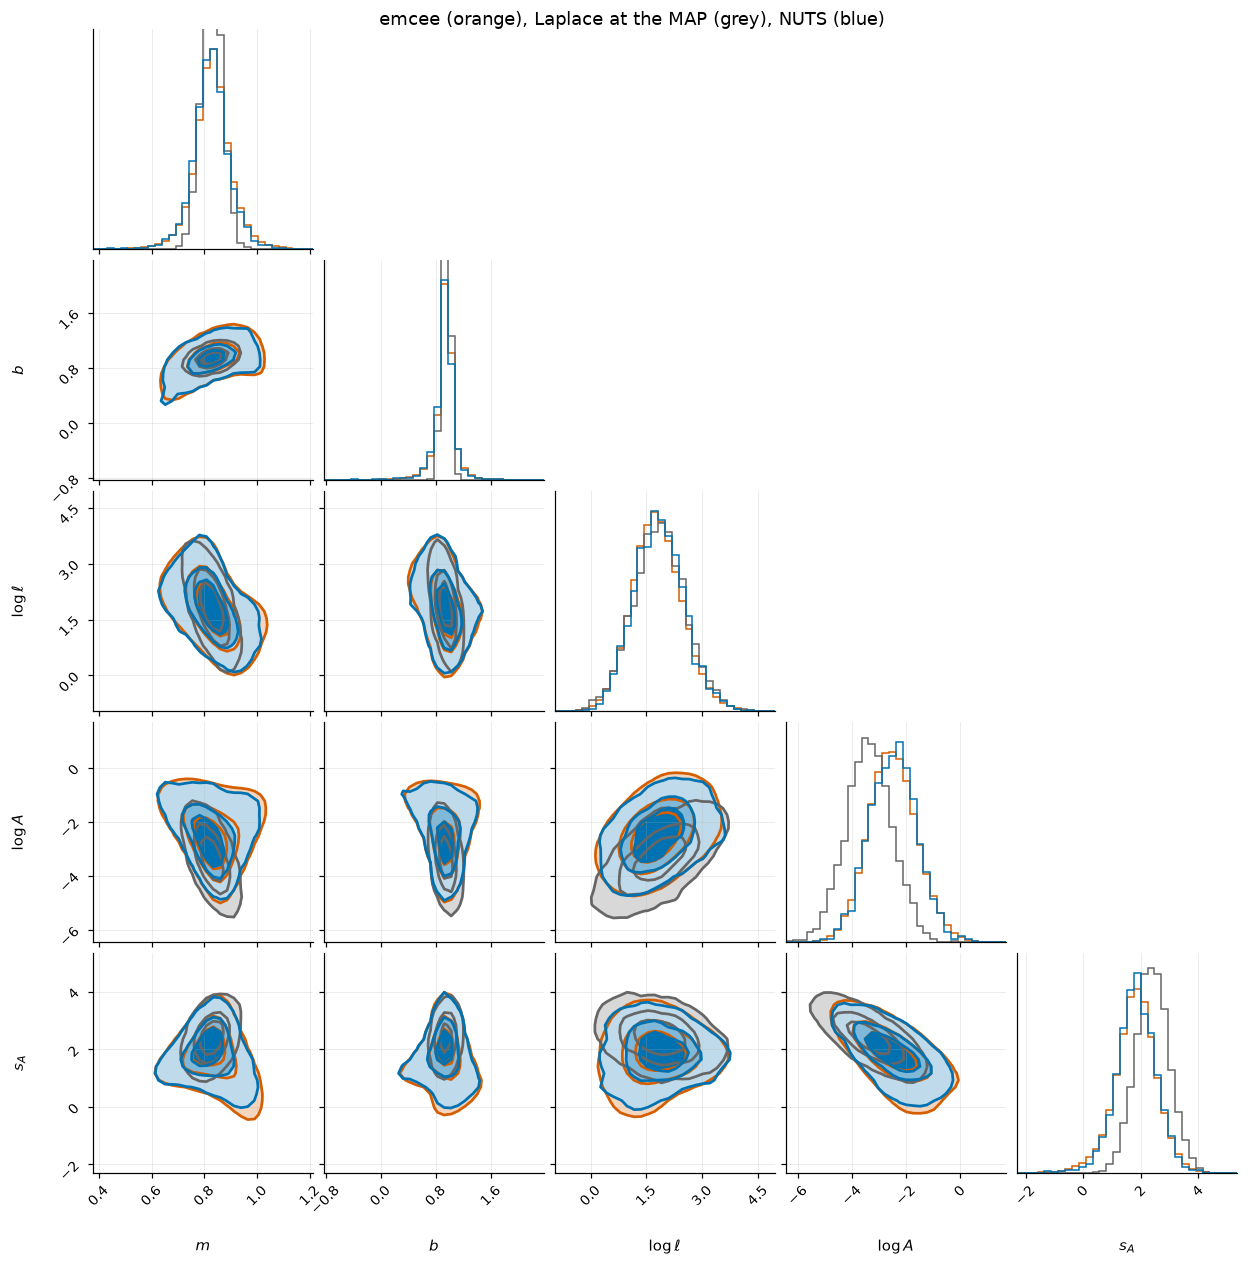

In [12]:
laplace = np.random.default_rng(4).multivariate_normal(g_map.x, laplace_cov, 4000)
overlay(
    [
        g_emcee.reshape(-1, gp_problem.ndim),
        laplace,
        g_nuts.reshape(-1, gp_problem.ndim),
    ],
    [plotstyle.COLOURS[1], "0.4", plotstyle.COLOURS[0]],
    [f"${p.latex}$" for p in gp_problem.params],
    "emcee (orange), Laplace at the MAP (grey), NUTS (blue)",
)

In [13]:
print("posterior standard deviations")
for k, name in enumerate(gp_problem.names):
    print(
        f"  {name:10s} Laplace {np.sqrt(laplace_cov[k, k]):.3f}   "
        f"NUTS {g_nuts[..., k].std():.3f}   emcee {g_emcee[..., k].std():.3f}"
    )

posterior standard deviations
  m          Laplace 0.040   NUTS 0.070   emcee 0.074
  b          Laplace 0.057   NUTS 0.176   emcee 0.190
  log_ell    Laplace 0.701   NUTS 0.667   emcee 0.673
  log_A      Laplace 0.854   NUTS 0.870   emcee 0.891
  amp_slope  Laplace 0.588   NUTS 0.696   emcee 0.742


The MAP takes under two seconds.  Started around it, NUTS gives 625 effective draws in about half a minute, with $\hat R$ of 1.007 and no divergences.  The target acceptance rate of 0.95 matters here.  At blackjax's default of 0.8, the run printed above gave 85 divergences in 4000 draws, and an $\hat R$ of 1.016: trajectories that met the sharp curvature where a small amplitude leaves the length scale unconstrained.  A run with divergences can under-explore exactly there, and on the benchmark's GP problem, whose exact posterior is known, NUTS's widths came out 0.23 standard deviations too narrow with a similar number of divergences.  A higher target means smaller steps, more gradient evaluations per draw, and no divergences.

emcee is cheap in five dimensions, but it needs a longer run than it first appears to.  At 10 000 steps (printed above) its $\tau$ of about 130 steps just passes emcee's own $50\tau$ rule, yet the rank-normalised split $\hat R$ is 1.03: the walkers drift together, slowly enough for the $50\tau$ rule to miss it.  At 30 000 steps it passes both, with 4714 effective draws in under a minute, about five times NUTS's rate.  On a problem this small emcee is the better choice, provided we check it with split $\hat R$, and the two posteriors agree: their widths are within about 10 % of each other.

The Laplace approximation gets the length scale's width roughly right ($\log\ell$ 0.70 against 0.67 from NUTS), but not the line's: $m$ comes out 0.040 against 0.070, and $b$ 0.057 against 0.176.  The posterior is not Gaussian.  It puts more mass at larger amplitudes than the mode does — its $\log A$ marginal sits nearly a unit above the Laplace Gaussian, which is centred on the mode at $-3.36$ — and a larger amplitude lets the line move further.  A curvature taken at the mode cannot see that.  Laplace is a quick check of where the posterior is, not a substitute for sampling it.

## Takeaways

- **Choose the sampler by the problem.**  With many parameters and a smooth posterior, NUTS wins outright: the 33-parameter hierarchy converged in about half a minute, while emcee had not converged after a minute.  With a handful of parameters, emcee is cheap and as good, given a long enough run.  For reaction models with local modes, or when the evidence is wanted, the notebooks use pocomc, which the [benchmark](/benchmarks.md) finds correct and fastest there.
- **Gradient samplers need the unconstrained density.**  `log_posterior_unconstrained` and `to_theta` handle every bound, including those implied by a prior (recipe 41).
- **Read the diagnostics before the ESS.**  An ESS means something only when the rank-normalised split $\hat R$ is below about 1.01 and, for NUTS, there are no divergences; raising the target acceptance rate is the first cure.  For emcee, also check that the run is longer than $50\tau$, and remember that the two checks catch different things: on the GP, the $50\tau$ rule passed a run that split $\hat R$ rejected.
- **Start where the problem allows.**  On a hierarchy the MLE is a ridge rather than a point, and the MAP is not typical of the posterior, so both samplers start from prior draws.
- **The Laplace approximation is a quick check.**  The exact Hessian makes it nearly free, but it misses the width that a non-Gaussian posterior adds.

The benchmark behind these numbers, on more problems and scored against exact or long-run reference posteriors, is `benchmarks/bench_samplers.py`; its tables are on the [benchmarks](/benchmarks.md) page.